#Phần 1: Huấn luyện và phân loại bộ số MNIST


In [22]:
import matplotlib.pyplot as plt
from sklearn import datasets, metrics, tree
from sklearn.model_selection import train_test_split

HO_TEN = "Nguyễn Gia Huy"
MSSV = "6451071027"
print(HO_TEN, "-", MSSV)

Nguyễn Gia Huy - 6451071027


## 1. Tải bộ dữ liệu MNIST từ sklearn

In [23]:
print(HO_TEN, "-", MSSV)
digits = datasets.load_digits()
print("\nTổng số mẫu ảnh MNIST trong dataset:", len(digits.images))

Nguyễn Gia Huy - 6451071027

Tổng số mẫu ảnh MNIST trong dataset: 1797


## 2. Hiển thị 4 mẫu đầu tiên

Nguyễn Gia Huy - 6451071027


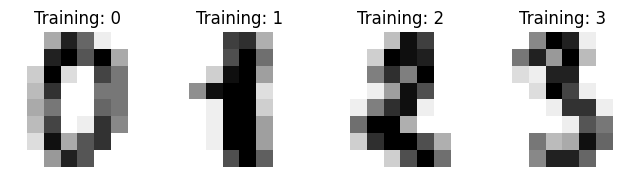

In [24]:
print(HO_TEN, "-", MSSV)
_, axes = plt.subplots(1, 4, figsize=(8, 3))
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes, images_and_labels[:4]):
  ax.set_axis_off()
  ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
  ax.set_title('Training: %i' % label)
plt.show()

## 3. Biến đổi ma trận ảnh 8x8 thành vector 1D (1x64)

In [25]:
print(HO_TEN, "-", MSSV)
n_samples = len(digits.images)
data_mnist = digits.images.reshape((n_samples, -1))


Nguyễn Gia Huy - 6451071027


## 4. Tạo mô hình Cây ID3 và chia tập dữ liệu (80% Train, 20% Test)

In [26]:
print(HO_TEN, "-", MSSV)
classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)
X_train_digits, X_test_digits, y_train_digits, y_test_digits = (
    train_test_split(data_mnist, digits.target, test_size=0.2, shuffle=False)
)


Nguyễn Gia Huy - 6451071027


## 5. Huấn luyện mô hình và dự đoán

In [27]:
print(HO_TEN, "-", MSSV)
classifier.fit(X_train_digits, y_train_digits)
predicted_digits = classifier.predict(X_test_digits)

print(
    "\nAccuracy Score:",
    metrics.accuracy_score(y_test_digits, predicted_digits),
)
print("\nClassification report:\n")
print(metrics.classification_report(y_test_digits, predicted_digits))


Nguyễn Gia Huy - 6451071027

Accuracy Score: 0.7972222222222223

Classification report:

              precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.72      0.64      0.68        36
           2       0.76      0.74      0.75        35
           3       0.69      0.59      0.64        37
           4       0.86      0.84      0.85        37
           5       0.80      0.95      0.86        37
           6       0.97      0.95      0.96        37
           7       0.78      0.86      0.82        36
           8       0.79      0.82      0.81        33
           9       0.72      0.70      0.71        37

    accuracy                           0.80       360
   macro avg       0.80      0.80      0.79       360
weighted avg       0.80      0.80      0.79       360



## Ma trận nhầm lẫn

Nguyễn Gia Huy - 6451071027


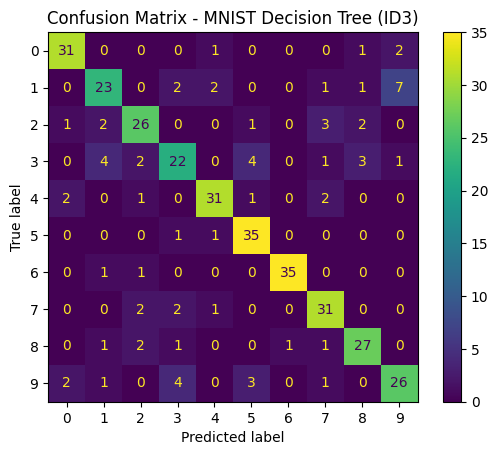

In [28]:
print(HO_TEN, "-", MSSV)
metrics.ConfusionMatrixDisplay.from_predictions(y_test_digits, predicted_digits)
plt.title("Confusion Matrix - MNIST Decision Tree (ID3)")
plt.show()

#Phần 2: Nhận dạng ảnh chụp chữ số thực tế

In [29]:
print(HO_TEN, "-", MSSV)
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps


Nguyễn Gia Huy - 6451071027


## 1. Đọc file ảnh chụp thực tế và tiền xử lý

In [30]:
print(HO_TEN, "-", MSSV)
img_path = 'test_image_Bai7.jpg'
img = Image.open(img_path).convert("L").resize((8, 8))
img = ImageOps.invert(img)

Nguyễn Gia Huy - 6451071027


## 2. Chuyển sang mảng 1D (1x64) và phân ngưỡng đen/trắng (Thresholding)

In [31]:
print(HO_TEN, "-", MSSV)
im2arr = np.array(img)
img1d = im2arr.reshape([1, 64])
img1d[img1d > 109] = 155
img1d[img1d < 110] = 0

Nguyễn Gia Huy - 6451071027


## 3. Hiển thị hình ảnh sau xử lý

Nguyễn Gia Huy - 6451071027


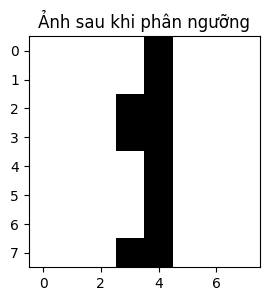

In [32]:
print(HO_TEN, "-", MSSV)
plt.figure(figsize=(3, 3))
plt.imshow(img1d.reshape((8, 8)), cmap=plt.cm.gray_r, interpolation='nearest')
plt.title("Ảnh sau khi phân ngưỡng")
plt.show()

## 4. Đưa vào mô hình Cây ID3 đã huấn luyện ở Phần 1 để dự đoán

In [33]:
print(HO_TEN, "-", MSSV)
y_pred_digit = classifier.predict(img1d)
print("\n=== KẾT QUẢ NHẬN DẠNG KÝ TỰ ===")
print("Chữ số dự đoán từ bức ảnh chụp thực tế là:", y_pred_digit[0])

Nguyễn Gia Huy - 6451071027

=== KẾT QUẢ NHẬN DẠNG KÝ TỰ ===
Chữ số dự đoán từ bức ảnh chụp thực tế là: 1
